# Lab 04 · Mạng nơ-ron nhiều lớp (MLP) và nhận dạng chữ số viết tay MNIST



## Mục tiêu

Sau bài lab, bạn có thể:

1. Xây dựng MLP bằng PyTorch (`nn.Linear`, `nn.Sequential`), nhưng **tự cài đặt toàn bộ lan truyền ngược** .
2. Kiểm chứng gradient bằng  autograd của PyTorch.
3. Tự viết bộ tối ưu SGD + momentum và huấn luyện mạng trên MNIST .
4. Điều chỉnh siêu tham số có cơ sở và so sánh các kỹ thuật khác.
5. Khai phá dữ liệu MNIST .



**Nộp bài:** file `.ipynb` đã chạy lại từ đầu (*Kernel → Restart & Run All*), giữ nguyên output.

*Tham khảo:* bài tập Neural Networks I đến III của [Pattern Recognition Handbook](https://github.com/Wickstrom/pattern-recognition-handbook) (K. Wickstrøm, UiT, MIT License).

## Quy tắc "from scratch"

Thư viện được dùng để **chứa tham số và tính lan truyền thuận**. Mọi thứ liên quan tới **gradient** bạn phải tự viết.

| Được dùng thư viện | Tự cài đặt |
|---|---|
| `nn.Linear`, `nn.Sequential`, các module kích hoạt khi chạy forward | Toàn bộ backward: BP1 đến BP4, đạo hàm ReLU, sigmoid, tanh, δ của softmax + cross-entropy |
| `nn.init` (Xavier, He) | Bộ tối ưu SGD + momentum (Δw ở trang 65) |
| `torchvision` để tải MNIST | Inverted dropout (forward và backward), số hạng L2 trong gradient |
| Autograd và `torch.optim`, **chỉ** trong ô kiểm chứng 3.2, bài 8.2 và bonus B1 | Vòng lặp huấn luyện, early stopping |

**Cấm** dùng `loss.backward()`, `torch.autograd`, `torch.optim`, `torch.enable_grad()` ở mọi ô khác. Ô đầu tiên của notebook gọi `torch.set_grad_enabled(False)`, nên mọi lệnh `loss.backward()` sẽ báo lỗi ngay. Khi chấm, giảng viên chạy script quét tự động; phần nào vi phạm sẽ không được tính điểm.

Các ô kiểm tra cho sẵn mang nhãn `cho-san-khong-sua`: không sửa nội dung, script chấm so khớp với bản gốc. Ô duy nhất được dùng autograd là ô 3.2 (nhãn `cho-phep-autograd`, cũng là ô cho sẵn). Riêng các ô của bài 8.2 (nhãn `bai-tap-autograd`) và bonus B1 (nhãn `bonus-autograd`) thì bạn tự viết và được dùng autograd, `torch.optim`.

## Phần 0. Chuẩn bị dữ liệu (cho sẵn)

In [1]:
import os, gzip, shutil, time, copy, urllib.request
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torchvision

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

# TAT autograd cho toan bo notebook: gradient phai do ban tu tinh.
torch.set_grad_enabled(False)

print("PyTorch", torch.__version__, "| so luong CPU threads:", torch.get_num_threads())

PyTorch 2.15.0+cpu | so luong CPU threads: 8


Hàm `load_mnist` thử tải qua `torchvision` trước. Nếu nguồn mặc định không truy cập được, hàm tự chuyển sang một bản sao trên GitHub (cùng 4 file gốc, cùng md5).

In [2]:
DATA_ROOT = "./data"
MNIST_FILES = ["train-images-idx3-ubyte", "train-labels-idx1-ubyte",
               "t10k-images-idx3-ubyte", "t10k-labels-idx1-ubyte"]
GITHUB_MIRROR = "https://raw.githubusercontent.com/fgnt/mnist/master/"


def _download_from_mirror(root):
    raw = os.path.join(root, "MNIST", "raw")
    os.makedirs(raw, exist_ok=True)
    for name in MNIST_FILES:
        dst = os.path.join(raw, name)
        if os.path.exists(dst):
            continue
        gz = dst + ".gz"
        urllib.request.urlretrieve(GITHUB_MIRROR + name + ".gz", gz)
        with gzip.open(gz, "rb") as f_in, open(dst, "wb") as f_out:
            shutil.copyfileobj(f_in, f_out)


def load_mnist(root=DATA_ROOT):
    try:
        train = torchvision.datasets.MNIST(root, train=True, download=True)
        test = torchvision.datasets.MNIST(root, train=False, download=True)
    except Exception as e:
        print("Nguon mac dinh cua torchvision loi (", type(e).__name__, "), chuyen sang mirror GitHub")
        _download_from_mirror(root)
        train = torchvision.datasets.MNIST(root, train=True, download=False)
        test = torchvision.datasets.MNIST(root, train=False, download=False)
    return train.data, train.targets, test.data, test.targets


Xtr_raw, ytr_raw, Xte_raw, yte_raw = load_mnist()
print("train:", tuple(Xtr_raw.shape), "| test:", tuple(Xte_raw.shape))

100.0%
100.0%
100.0%
100.0%

train: (60000, 28, 28) | test: (10000, 28, 28)


**Chia dữ liệu.** 60 000 ảnh huấn luyện được chia ngẫu nhiên thành 50 000 ảnh *train* và 10 000 ảnh *validation*. Mọi lựa chọn siêu tham số chỉ dựa trên validation. Tập *test* (10 000 ảnh) chỉ được dùng **một lần** ở Phần 7.

**Tiền xử lý.** Mỗi ảnh 28 × 28 được duỗi thành vector $\mathbf{x} \in \mathbb{R}^{784}$, chia cho 255 rồi chuẩn hoá bằng trung bình và độ lệch chuẩn tính **chỉ trên tập train**, để không rò rỉ thông tin từ validation hay test.

In [3]:
g = torch.Generator().manual_seed(SEED)
perm = torch.randperm(len(Xtr_raw), generator=g)
tr_idx, va_idx = perm[:50000], perm[50000:]

_X = Xtr_raw[tr_idx].reshape(-1, 784).float() / 255.0
MEAN, STD = _X.mean().item(), _X.std().item()


def preprocess(X_raw):
    return (X_raw.reshape(-1, 784).float() / 255.0 - MEAN) / STD


X_train, y_train = preprocess(Xtr_raw[tr_idx]), ytr_raw[tr_idx]
X_val, y_val = preprocess(Xtr_raw[va_idx]), ytr_raw[va_idx]
X_test, y_test = preprocess(Xte_raw), yte_raw

print(f"MEAN = {MEAN:.4f}, STD = {STD:.4f}")
print("X_train", tuple(X_train.shape), "| X_val", tuple(X_val.shape), "| X_test", tuple(X_test.shape))
print("So mau moi lop (train):", torch.bincount(y_train).tolist())

MEAN = 0.1307, STD = 0.3082
X_train (50000, 784) | X_val (10000, 784) | X_test (10000, 784)
So mau moi lop (train): [4923, 5613, 4958, 5093, 4863, 4546, 4933, 5204, 4882, 4985]


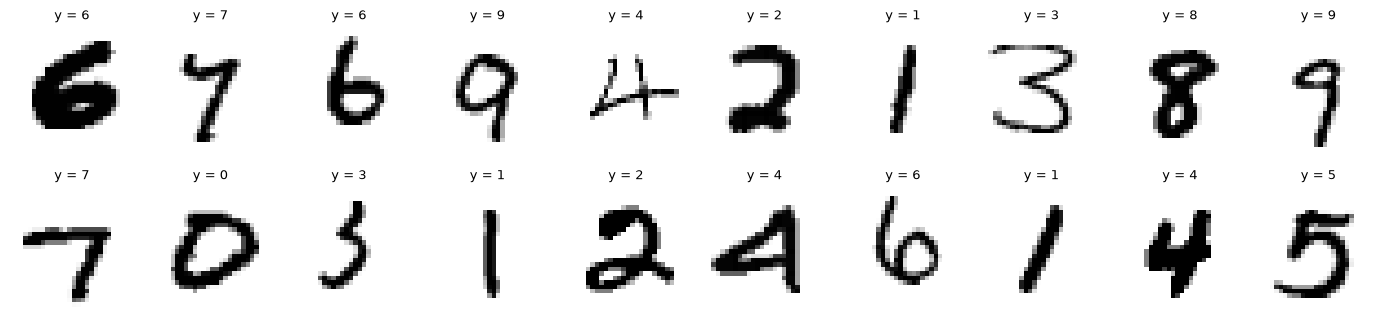

In [4]:
# Cac ham ve hinh dung chung cho ca notebook
def show_images(X, titles, n_cols=10, size=1.4):
    n = len(X)
    n_rows = int(np.ceil(n / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(size * n_cols, size * 1.25 * n_rows))
    for ax in np.array(axes).reshape(-1):
        ax.axis("off")
    for k in range(n):
        ax = np.array(axes).reshape(-1)[k]
        ax.imshow((X[k] * STD + MEAN).reshape(28, 28), cmap="gray_r")
        ax.set_title(titles[k], fontsize=9)
    plt.tight_layout()
    plt.show()


def plot_history(histories, title=""):
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    for name, h in histories.items():
        ep = np.arange(1, len(h["val_loss"]) + 1)
        line, = axes[0].plot(ep, h["train_loss"], "-", label=f"{name} (train)")
        axes[0].plot(ep, h["val_loss"], "--", color=line.get_color(), label=f"{name} (val)")
        axes[1].plot(ep, h["train_acc"], "-", color=line.get_color())
        axes[1].plot(ep, h["val_acc"], "--", color=line.get_color())
    axes[0].set_xlabel("epoch"); axes[0].set_ylabel("cross-entropy")
    axes[1].set_xlabel("epoch"); axes[1].set_ylabel("accuracy")
    axes[0].legend(fontsize=8)
    axes[1].set_title("net lien: train, net dut: val", fontsize=9)
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


def plot_heatmap(M, row_labels, col_labels, row_name, col_name, title, cell_note=None):
    fig, ax = plt.subplots(figsize=(1.6 * len(col_labels) + 2, 0.9 * len(row_labels) + 1.5))
    ax.imshow(np.nan_to_num(M, nan=np.nanmin(M) if np.isfinite(M).any() else 0), cmap="viridis")
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            txt = "phan ky" if np.isnan(M[i, j]) else f"{M[i, j]:.4f}"
            if cell_note is not None:
                txt += "\n" + cell_note(i, j)
            ax.text(j, i, txt, ha="center", va="center", fontsize=8,
                    color="white" if np.isnan(M[i, j]) or M[i, j] < np.nanmedian(M) else "black")
    ax.set_xticks(range(len(col_labels))); ax.set_xticklabels(col_labels)
    ax.set_yticks(range(len(row_labels))); ax.set_yticklabels(row_labels)
    ax.set_xlabel(col_name); ax.set_ylabel(row_name); ax.set_title(title)
    plt.tight_layout()
    plt.show()


show_images(X_train[:20], [f"y = {int(t)}" for t in y_train[:20]])

## Phần 1. Thiết kế mạng và lan truyền thuận (0.5 điểm)

### 1.1 Mạng được dựng bằng thư viện (cho sẵn)

Ta dùng lại ký hiệu ở trang 22 và 26 của bài giảng. Với một mini-batch gồm $N$ mẫu xếp thành hàng:

$$\mathbf{Z}^{(l)} = \mathbf{A}^{(l-1)} \big(\mathbf{W}^{(l)}\big)^{\top} + \mathbf{b}^{(l)}, \qquad \mathbf{A}^{(l)} = f\big(\mathbf{Z}^{(l)}\big), \qquad \mathbf{A}^{(0)} = \mathbf{X}.$$

`nn.Linear(k_in, k_out)` tính đúng phép biến đổi đầu tiên. Thuộc tính `weight` của nó có kích thước $k_l \times k_{l-1}$, khớp với $\mathbf{W}^{(l)}$ trong bài giảng. Trong `nn.Sequential`, hàm kích hoạt là một module **riêng** đứng sau `nn.Linear`. Lớp ra không có hàm kích hoạt: softmax được gộp vào hàm mất mát ở Phần 2.

Hàm `build_mlp` dưới đây được cho sẵn. Khởi tạo He dùng độ lệch chuẩn $\sqrt{2/k_{\text{in}}}$, còn Xavier dùng phân phối đều trên $\pm\sqrt{6/(k_{\text{in}} + k_{\text{out}})}$ (trang 73, 74).

In [5]:
ACTIVATIONS = {"relu": nn.ReLU, "sigmoid": nn.Sigmoid, "tanh": nn.Tanh}


def build_mlp(sizes, activation="relu", p_drop=0.0, init="he", const=0.01, seed=SEED):
    """sizes = [784, k_1, ..., k_{L-1}, 10]. Tra ve nn.Sequential:
    Linear -> Act -> (Dropout) -> ... -> Linear (lop ra khong co ham kich hoat)."""
    torch.manual_seed(seed)
    layers = []
    L = len(sizes) - 1
    for l in range(L):
        lin = nn.Linear(sizes[l], sizes[l + 1])
        if init == "he":
            nn.init.kaiming_normal_(lin.weight, nonlinearity="relu")   # std = sqrt(2 / k_in)
        elif init == "xavier":
            nn.init.xavier_uniform_(lin.weight)                         # U(-sqrt(6/(k_in+k_out)), +...)
        elif init == "const":
            nn.init.constant_(lin.weight, const)                        # chi dung de minh hoa doi xung
        else:
            raise ValueError(init)
        nn.init.zeros_(lin.bias)
        layers.append(lin)
        if l < L - 1:
            layers.append(ACTIVATIONS[activation]())
            if p_drop > 0:
                layers.append(nn.Dropout(p_drop))
    return nn.Sequential(*layers)


def n_params(model):
    return sum(p.numel() for p in model.parameters())


demo = build_mlp([784, 256, 128, 10], p_drop=0.2)
print(demo)
print("So tham so:", n_params(demo))

Sequential(
  (0): Linear(in_features=784, out_features=256, bias=True)
  (1): ReLU()
  (2): Dropout(p=0.2, inplace=False)
  (3): Linear(in_features=256, out_features=128, bias=True)
  (4): ReLU()
  (5): Dropout(p=0.2, inplace=False)
  (6): Linear(in_features=128, out_features=10, bias=True)
)
So tham so: 235146


### 1.2 Lan truyền thuận có cache (TODO)

Backward cần lại các đại lượng của forward (bước 2 ở trang 53: tính **và lưu lại** mọi $\mathbf{z}^{(l)}, \mathbf{a}^{(l)}$). Hàm `forward_with_cache` duyệt từng module của `nn.Sequential` và lưu vào `cache` một bộ `(layer, a_in, a_out, extra)`:

* `a_in`: đầu vào của module, `a_out`: đầu ra của module;
* `extra`: mặt nạ dropout $\mathbf{M}$ với module `nn.Dropout` khi huấn luyện, `None` trong mọi trường hợp khác.

Với các module thường, bạn được gọi thẳng `layer(a_in)`. Riêng `nn.Dropout`, bạn **tự cài inverted dropout** để biết mặt nạ (cần cho backward):

$$\mathbf{M} \sim \text{Bernoulli}(1 - p), \qquad \mathbf{A}_{\text{out}} = \frac{\mathbf{A}_{\text{in}} \odot \mathbf{M}}{1 - p} \quad (\text{khi huấn luyện}), \qquad \mathbf{A}_{\text{out}} = \mathbf{A}_{\text{in}} \quad (\text{khi đánh giá}).$$

Chia cho $1 - p$ giữ nguyên kỳ vọng của tín hiệu, nên lúc đánh giá không cần nhân thêm hệ số nào.

In [6]:
def forward_with_cache(model, X, train=True):
    """Tra ve (output cua mang, cache). cache[i] = (layer, a_in, a_out, extra)."""
    cache = []
    a = X
    for layer in model:
        a_in = a
        extra = None
        if isinstance(layer, nn.Dropout):
            # TODO (1.2b): inverted dropout
            #   - neu train va layer.p > 0: sinh mat na M (0/1, cung shape a_in) voi P(M = 1) = 1 - p,
            #     tinh a = a_in * M / (1 - p), luu M vao extra
            #   - nguoc lai: a = a_in
            raise NotImplementedError("1.2b: inverted dropout")
        else:
            # TODO (1.2a): tinh dau ra cua module (duoc goi thang layer(a_in))
            raise NotImplementedError("1.2a: forward cua module")
        cache.append((layer, a_in, a, extra))
    return a, cache

In [7]:
# KIEM TRA PHAN 1 (cho san)
_m = build_mlp([784, 64, 10])
_out, _cache = forward_with_cache(_m, X_train[:8], train=False)
assert torch.allclose(_out, _m(X_train[:8])), "Output khac voi model(X)"
assert len(_cache) == len(_m), "Moi module phai co dung mot phan tu trong cache"
assert _cache[1][1] is _cache[0][2], "a_in cua module sau phai la a_out cua module truoc"

_md = build_mlp([784, 64, 10], p_drop=0.5).eval()
_o, _c = forward_with_cache(_md, X_train[:512], train=False)
assert torch.allclose(_o, _md(X_train[:512])) and _c[2][3] is None, "Khi danh gia, dropout khong duoc lam gi"

torch.manual_seed(0)
_o, _c = forward_with_cache(_md, X_train[:512], train=True)
_layer, _a_in, _a_out, _M = _c[2]
assert _M is not None and set(_M.unique().tolist()) <= {0.0, 1.0}, "Mat na phai gom 0 va 1"
assert abs(_M.mean().item() - 0.5) < 0.02, "Ti le giu lai phai xap xi 1 - p"
assert torch.allclose(_a_out, _a_in * _M / 0.5), "Chua chia cho (1 - p)"
print("Phan 1: OK")

NotImplementedError: 1.2a: forward cua module

## Phần 2. Lan truyền ngược from scratch (2.5 điểm)



### 2.1 Softmax + cross-entropy (TODO)

Trừ giá trị lớn nhất của mỗi hàng trước khi lấy `exp` để tránh tràn số (trang 69). Hàm trả về mất mát trung bình và $\boldsymbol{\Delta}^{(L)}$.

In [ ]:
def softmax_cross_entropy(logits, y):
    """logits: (N, K), y: (N,) nhan nguyen 0..K-1.
    Tra ve (loss, delta): loss = trung binh cross-entropy (tensor 0 chieu),
    delta = dJ/dlogits, kich thuoc (N, K)."""
    N = logits.shape[0]
    z = logits - logits.max(dim=1, keepdim=True).values          # tru max de tranh tran so
    log_probs = z - torch.log(torch.exp(z).sum(dim=1, keepdim=True))
    loss = -log_probs[torch.arange(N), y].mean()
    Y = torch.zeros_like(logits)
    Y[torch.arange(N), y] = 1.0                                    # one-hot (trang 71)
    delta = (torch.exp(log_probs) - Y) / N                         # BP1: (Y_hat - Y) / N
    return loss, delta

In [ ]:
# KIEM TRA 2.1 (cho san): dung vi du meo / cho / chim o trang 70 va 72
_z = torch.tensor([[2.0, 1.0, 0.1]])
_l, _d = softmax_cross_entropy(_z, torch.tensor([0]))
print("loss (lop dung = meo):", round(_l.item(), 4), "| delta:", _d.numpy().round(4))
assert abs(_l.item() - 0.4170) < 1e-3
assert torch.allclose(_d, torch.tensor([[0.6590 - 1, 0.2424, 0.0986]]), atol=1e-3)
_l2, _ = softmax_cross_entropy(_z, torch.tensor([2]))
print("loss (lop dung = chim):", round(_l2.item(), 4))
assert abs(_l2.item() - 2.317) < 2e-3
_lb, _db = softmax_cross_entropy(_z.repeat(2, 1), torch.tensor([0, 2]))
assert abs(_lb.item() - (_l.item() + _l2.item()) / 2) < 1e-6, "loss phai la trung binh tren batch"
assert torch.allclose(_db[0], _d[0] / 2), "delta phai chia cho N"
_lo, _do = softmax_cross_entropy(torch.tensor([[1000.0, 0.0, -1000.0]]), torch.tensor([0]))
assert torch.isfinite(_lo) and torch.isfinite(_do).all(), "Tran so: hay tru max truoc khi lay exp"
print("2.1: OK")

### 2.2 Backward của một lớp `nn.Linear` (TODO)

Đầu vào: $\mathbf{A}^{(l-1)}$ (`a_in`, kích thước $N \times k_{l-1}$) và $\boldsymbol{\Delta}^{(l)}$ (`delta`, $N \times k_l$). Đầu ra: $\partial J/\partial \mathbf{W}^{(l)}$ (cùng kích thước với `layer.weight`), $\partial J/\partial \mathbf{b}^{(l)}$, và $\mathbf{G}^{(l-1)} = \partial J / \partial \mathbf{A}^{(l-1)}$. Chỉ dùng nhân ma trận, không vòng lặp.

In [ ]:
def linear_backward(layer, a_in, delta):
    """Tra ve (dW, db, grad_in) cho mot lop nn.Linear (BP4, BP3 va nua dau cua BP2)."""
    # TODO (2.2): ba dong nhan ma tran. Kiem tra kich thuoc truoc khi chay!
    raise NotImplementedError("2.2: linear_backward")
    return dW, db, grad_in

### 2.3 Backward của hàm kích hoạt và dropout (TODO)

Mỗi hàm nhận gradient theo **đầu ra** của module và trả về gradient theo **đầu vào**. Để ý hàm nào dùng `a_in` (tức $\mathbf{Z}$), hàm nào dùng `a_out` (tức $\mathbf{A}$, giúp khỏi tính lại `exp`).

In [ ]:
def relu_backward(a_in, grad):
    raise NotImplementedError("2.3: relu_backward")   # TODO


def sigmoid_backward(a_out, grad):
    raise NotImplementedError("2.3: sigmoid_backward")  # TODO


def tanh_backward(a_out, grad):
    raise NotImplementedError("2.3: tanh_backward")   # TODO


def dropout_backward(mask, p, grad):
    """mask = None nghia la dropout khong hoat dong o forward."""
    raise NotImplementedError("2.3: dropout_backward")  # TODO

### 2.4 Vòng lặp backward (TODO)

Duyệt `cache` **từ cuối về đầu**. Với mỗi `nn.Linear`, gán gradient vào `layer.weight.grad` và `layer.bias.grad`; với các module khác, cập nhật gradient đang chảy ngược.

Tham số `weight_decay` $= \lambda$ thêm số hạng L2: mất mát được tối ưu là $J + \frac{\lambda}{2} \sum_{l} \|\mathbf{W}^{(l)}\|_F^2$, nên $\partial / \partial \mathbf{W}^{(l)}$ có thêm $\lambda \mathbf{W}^{(l)}$. Không áp L2 cho bias. Phần 6 sẽ dùng tham số này.

In [ ]:
def backward(cache, grad_out, weight_decay=0.0):
    """grad_out = dJ/d(output cua mang). Gan .grad cho moi tham so nn.Linear.
    Tra ve dJ/dX (gradient theo dau vao cua mang)."""
    grad = grad_out
    for layer, a_in, a_out, extra in reversed(cache):
        # TODO (2.4): phan nhanh theo loai module
        #   nn.Linear  -> linear_backward, gan layer.weight.grad (cong weight_decay * W) va layer.bias.grad
        #   nn.ReLU / nn.Sigmoid / nn.Tanh -> ham backward tuong ung (de y a_in hay a_out)
        #   nn.Dropout -> dropout_backward voi mat na luu trong extra
        raise NotImplementedError("2.4: backward")
    return grad

## Phần 3. Kiểm chứng gradient (1.0 điểm)



### 3.1 So với autograd của PyTorch

Một mạng nhỏ gồm đủ mọi loại module (ReLU, dropout, tanh, sigmoid), tính ở `float64`, có cả số hạng L2. Autograd chạy lại forward với **đúng mặt nạ dropout** lấy từ `cache` của bạn. Yêu cầu: sai số tương đối dưới $10^{-8}$ ở mọi tham số.

In [ ]:
torch.manual_seed(0)
net = nn.Sequential(nn.Linear(784, 32), nn.ReLU(), nn.Dropout(0.3),
                    nn.Linear(32, 16), nn.Tanh(),
                    nn.Linear(16, 12), nn.Sigmoid(),
                    nn.Linear(12, 10)).double()
Xb, yb, lam = X_train[:64].double(), y_train[:64], 1e-3

logits, cache = forward_with_cache(net, Xb, train=True)
loss, delta = softmax_cross_entropy(logits, yb)
backward(cache, delta, weight_decay=lam)
mine = [p.grad.clone() for p in net.parameters()]

with torch.enable_grad():
    a = Xb
    for layer, _, _, extra in cache:
        if isinstance(layer, nn.Dropout):
            a = a if extra is None else a * extra / (1 - layer.p)
        else:
            a = layer(a)
    ref = nn.functional.cross_entropy(a, yb)
    ref_total = ref + 0.5 * lam * sum((l.weight ** 2).sum() for l in net if isinstance(l, nn.Linear))
    ref_grads = torch.autograd.grad(ref_total, list(net.parameters()))

assert abs(loss.item() - ref.item()) < 1e-10, "Loss khac voi cross_entropy cua PyTorch"
for (name, _), g_mine, g_ref in zip(net.named_parameters(), mine, ref_grads):
    rel = ((g_mine - g_ref).norm() / (g_mine.norm() + g_ref.norm() + 1e-30)).item()
    print(f"{name:>10}: sai so tuong doi = {rel:.2e}")
    assert rel < 1e-8, f"Gradient sai o {name}"
print("3.2: OK")

## Phần 4. Bộ tối ưu và vòng lặp huấn luyện (1.5 điểm)

### 4.1 SGD + momentum (TODO)

Theo trang 65:

$$\Delta\mathbf{w}(t) = \alpha\, \Delta\mathbf{w}(t-1) - \gamma\, \frac{\partial J}{\partial \mathbf{w}}, \qquad \mathbf{w}(t+1) = \mathbf{w}(t) + \Delta\mathbf{w}(t), \qquad \Delta\mathbf{w}(0) = \mathbf{0}.$$

Với $\alpha = 0$ ta có gradient descent thường. Cập nhật tham số **tại chỗ** (in-place, ví dụ `p.add_(...)`), vì autograd đã tắt nên không có gì cản trở.

In [ ]:
class SGDMomentum:
    def __init__(self, params, lr, momentum=0.0):
        self.params = list(params)
        self.lr, self.momentum = lr, momentum
        self.velocity = [torch.zeros_like(p) for p in self.params]   # Delta_w(0) = 0

    def step(self):
        for p, v in zip(self.params, self.velocity):
            v.mul_(self.momentum).sub_(self.lr * p.grad)   # Delta_w = alpha * Delta_w - gamma * g
            p.add_(v)                                      # w = w + Delta_w

    def zero_grad(self):
        for p in self.params:
            p.grad = None

In [ ]:
# KIEM TRA 4.1 (cho san)
_w = nn.Parameter(torch.tensor([1.0]))
_opt = SGDMomentum([_w], lr=0.1, momentum=0.9)
_w.grad = torch.tensor([2.0]); _opt.step()          # Delta = -0.2,               w = 0.8
assert torch.allclose(_w.data, torch.tensor([0.8]))
_w.grad = torch.tensor([2.0]); _opt.step()          # Delta = 0.9*(-0.2) - 0.2 = -0.38, w = 0.42
assert torch.allclose(_w.data, torch.tensor([0.42])), "Sai cong thuc momentum"
print("4.1: OK")

### 4.2 Một epoch huấn luyện (TODO)

Viết lại "công thức nấu ăn" 6 bước ở trang 53 cho mini-batch: xáo trộn dữ liệu, rồi với mỗi batch: forward (có cache), tính mất mát và $\boldsymbol{\Delta}^{(L)}$, backward, cập nhật. Hàm trả về cross-entropy trung bình (có trọng số theo số mẫu) trên các batch.

Hàm `evaluate` và hàm điều phối `train_model` được cho sẵn. `train_model` dừng sớm nếu mất mát thành `nan` hoặc `inf` (phân kỳ).

Khác với trang 60 (mỗi bước dùng toàn bộ dữ liệu, tức full-batch), lab dùng mini-batch vì MNIST có 50 000 ảnh: mỗi epoch gồm nhiều bước cập nhật, mỗi bước dùng một nhóm nhỏ ảnh đã xáo trộn.

In [ ]:
def train_one_epoch(model, X, y, optimizer, batch_size=128, weight_decay=0.0):
    N = X.shape[0]
    perm = torch.randperm(N)
    total, count = 0.0, 0
    for start in range(0, N, batch_size):
        idx = perm[start:start + batch_size]
        logits, cache = forward_with_cache(model, X[idx], train=True)   # buoc 2: forward
        loss, delta = softmax_cross_entropy(logits, y[idx])             # buoc 3: mat mat, BP1
        backward(cache, delta, weight_decay)                            # buoc 4, 5: BP2 den BP4
        optimizer.step()                                                # buoc 6: cap nhat
        total += loss.item() * len(idx)
        count += len(idx)
    return total / count

In [ ]:
def evaluate(model, X, y, batch_size=5000):
    """Tra ve (cross-entropy trung binh, accuracy). Dropout tat (train=False)."""
    total, correct = 0.0, 0
    for s in range(0, len(X), batch_size):
        logits, _ = forward_with_cache(model, X[s:s + batch_size], train=False)
        loss, _ = softmax_cross_entropy(logits, y[s:s + batch_size])
        total += loss.item() * len(logits)
        correct += (logits.argmax(dim=1) == y[s:s + batch_size]).sum().item()
    return total / len(X), correct / len(X)


def train_model(model, epochs, lr, momentum=0.0, batch_size=128, weight_decay=0.0,
                X_tr=None, y_tr=None, X_va=None, y_va=None, optimizer=None,
                seed=SEED, verbose=True):
    X_tr = X_train if X_tr is None else X_tr
    y_tr = y_train if y_tr is None else y_tr
    X_va = X_val if X_va is None else X_va
    y_va = y_val if y_va is None else y_va
    torch.manual_seed(seed)
    opt = optimizer if optimizer is not None else SGDMomentum(model.parameters(), lr, momentum)
    hist = {k: [] for k in ["train_loss", "train_acc", "val_loss", "val_acc", "time"]}
    for ep in range(1, epochs + 1):
        t0 = time.time()
        train_one_epoch(model, X_tr, y_tr, opt, batch_size, weight_decay)
        dt = time.time() - t0
        tl, ta = evaluate(model, X_tr, y_tr)
        vl, va = evaluate(model, X_va, y_va)
        for k, v in zip(hist, [tl, ta, vl, va, dt]):
            hist[k].append(v)
        if verbose:
            print(f"epoch {ep:2d} | {dt:5.1f}s | train loss {tl:.4f} acc {ta:.4f} | val loss {vl:.4f} acc {va:.4f}")
        if not np.isfinite(tl):
            if verbose:
                print("Phan ky (loss = nan/inf), dung som.")
            break
    return hist

### 4.3 Baseline

Kiến trúc 784 → 256 → 128 → 10, ReLU, khởi tạo He, $\gamma = 0.05$, $\alpha = 0.9$, batch 128, 10 epoch. **Yêu cầu: val accuracy tốt nhất đạt ít nhất 97%.** Trên CPU laptop, mỗi epoch mất khoảng 1 đến 3 giây.

ReLU và khởi tạo He mới được giới thiệu ngắn ở trang 41 và 74; lab dùng chúng làm mặc định vì chúng tránh được vanishing gradient (Phần 5.4 sẽ kiểm chứng).

In [ ]:
baseline = build_mlp([784, 256, 128, 10], activation="relu", init="he")
hist_base = train_model(baseline, epochs=10, lr=0.05, momentum=0.9, batch_size=128)
plot_history({"baseline": hist_base}, "Baseline 784-256-128-10")
best_val = max(hist_base["val_acc"])
print(f"Val accuracy tot nhat: {best_val:.4f}")
assert best_val >= 0.97, "Chua dat 97%: kiem tra lai Phan 2 va Phan 4"

# BTVN



## Phần 5. Điều chỉnh siêu tham số (1.0 điểm)

Quy tắc: mỗi thí nghiệm chỉ thay **một** yếu tố so với baseline, giữ nguyên seed, chọn theo **validation**, không đụng tới test. Mỗi lần chạy dùng 5 epoch để cả phần chạy trong vài phút. Viết code thí nghiệm ở các ô TODO; điểm dựa trên số liệu và biểu đồ mà ô code in ra.

### 5.1 Tốc độ học $\gamma$ và momentum $\alpha$

Huấn luyện baseline với mọi cặp $(\alpha, \gamma)$ trong lưới dưới đây và ghi val accuracy ở epoch cuối. Mỗi ô của heatmap có ghi kèm tốc độ học hiệu dụng $\gamma_{\text{eff}} = \gamma / (1 - \alpha)$ (trang 66, 67).

In [ ]:
LRS = [0.005, 0.01, 0.05, 0.1, 0.5]
MOMENTA = [0.0, 0.5, 0.9]
EPOCHS_SWEEP = 5
acc_lr = np.full((len(MOMENTA), len(LRS)), np.nan)

# TODO (5.1): voi moi (alpha, lr): build_mlp baseline moi, train_model(EPOCHS_SWEEP epoch, verbose=False),
#             ghi val_acc cuoi vao acc_lr[i, j]; de nan neu mo hinh phan ky.

plot_heatmap(acc_lr, [f"alpha={a}" for a in MOMENTA], [f"lr={l}" for l in LRS], "momentum", "learning rate",
             f"Val accuracy sau {EPOCHS_SWEEP} epoch",
             cell_note=lambda i, j: f"g_eff={LRS[j] / (1 - MOMENTA[i]):.3g}")

### 5.2 Kích thước batch

Giữ $\gamma = 0.05$, $\alpha = 0.9$ và 5 epoch, thay batch size. Ghi val accuracy cuối, thời gian trung bình mỗi epoch và tổng số lần cập nhật tham số.

In [ ]:
BATCH_SIZES = [16, 64, 256, 1024]
bs_rows = []   # moi phan tu: (batch_size, so lan cap nhat, giay/epoch, val acc)

# TODO (5.2): voi moi batch size, huan luyen baseline va them mot dong vao bs_rows

print(f"{'batch':>6} | {'so cap nhat':>11} | {'s/epoch':>7} | {'val acc':>7}")
for bs, nu, t, va in bs_rows:
    print(f"{bs:>6} | {nu:>11} | {t:7.2f} | {va:7.4f}")

### 5.3 Độ rộng và độ sâu

So các kiến trúc dưới đây (ReLU, He, $\gamma = 0.05$, $\alpha = 0.9$, 5 epoch). Ghi số tham số, train accuracy, val accuracy.

In [ ]:
ARCHS = [[784, 64, 10], [784, 256, 10], [784, 1024, 10], [784, 256, 128, 10], [784, 256, 256, 256, 256, 10]]
arch_rows = []   # (kien truc, so tham so, train acc, val acc)

# TODO (5.3)

print(f"{'kien truc':>24} | {'tham so':>9} | {'train acc':>9} | {'val acc':>7}")
for name, npar, ta, va in arch_rows:
    print(f"{name:>24} | {npar:>9,} | {ta:9.4f} | {va:7.4f}")

### 5.4 Hàm kích hoạt và vanishing gradient

Mạng sâu 784 → 128 × 6 → 10 với ba hàm kích hoạt: sigmoid và tanh khởi tạo Xavier, ReLU khởi tạo He. Trước khi huấn luyện, đo chuẩn Frobenius $\|\partial J / \partial \mathbf{W}^{(l)}\|_F$ của **từng lớp** trên một batch 512 ảnh, dùng chính hàm `backward` của bạn. Sau đó huấn luyện mỗi mạng 5 epoch.

In [ ]:
def layer_grad_norms(model, X, y):
    """Tra ve list ||dJ/dW^(l)||_F, tu lop dau den lop cuoi."""
    raise NotImplementedError("5.4: layer_grad_norms")   # TODO: forward -> loss -> backward -> doc .grad


DEEP = [784] + [128] * 6 + [10]
act_setups = {"sigmoid": "xavier", "tanh": "xavier", "relu": "he"}
grad_norms, hist_act = {}, {}
# TODO (5.4): voi moi act: grad_norms[act] = layer_grad_norms(mang moi, X_train[:512], y_train[:512])
#                        hist_act[act]  = train_model(mang moi khac, EPOCHS_SWEEP, lr=0.05, momentum=0.9, verbose=False)

fig, ax = plt.subplots(figsize=(8, 4))
w = 0.27
for k, act in enumerate(grad_norms):
    ax.bar(np.arange(1, len(DEEP)) + (k - 1) * w, grad_norms[act], width=w, label=act)
ax.set_yscale("log"); ax.set_xlabel("lop l"); ax.set_ylabel("||dJ/dW^(l)||  (log)")
ax.set_title("Chuan gradient tung lop luc khoi tao"); ax.legend()
plt.tight_layout(); plt.show()
for act, gn in grad_norms.items():
    print(f"{act:>7}: lop 1 = {gn[0]:.2e} | lop cuoi = {gn[-1]:.2e} | lop cuoi / lop 1 = {gn[-1] / gn[0]:.1f}")
if hist_act:
    plot_history(hist_act, "Mang sau 6 lop an")

### 5.5 Khởi tạo trọng số

**(a) Đối xứng.** Khởi tạo **mọi** trọng số bằng cùng một hằng số (mạng 784 → 64 → 10, tanh), huấn luyện 3 epoch, rồi đếm số hàng **khác nhau** của $\mathbf{W}^{(1)}$ (mỗi hàng là một nơ-ron ẩn). So với cùng mạng khởi tạo Xavier.

**(b) Xavier hay He cho ReLU.** Mạng 10 lớp ẩn, mỗi lớp 256 nơ-ron ReLU. Đo độ lệch chuẩn của đầu ra từng lớp ReLU lúc khởi tạo, trên 1 000 ảnh.

In [ ]:
# (a) Doi xung
sym = {}
# TODO (5.5a): voi init in ["const", "xavier"]: huan luyen 3 epoch,
#              dem so hang khac nhau cua W^(1) (goi y: torch.unique(..., dim=0)), luu (so hang, val acc) vao sym[init]
for init, (nd, va) in sym.items():
    print(f"{init:>7}: so noron an khac nhau = {nd:2d} / 64 | val acc = {va:.4f}")


# (b) Do lech chuan tin hieu qua cac lop ReLU
def relu_output_stds(model, X):
    _, cache = forward_with_cache(model, X, train=False)
    return [a_out.std().item() for layer, _, a_out, _ in cache if isinstance(layer, nn.ReLU)]


DEEP10 = [784] + [256] * 10 + [10]
fig, ax = plt.subplots(figsize=(7, 3.5))
for init in ["xavier", "he"]:
    stds = relu_output_stds(build_mlp(DEEP10, init=init), X_train[:1000])
    ax.plot(range(1, 11), stds, "o-", label=init)
    print(f"{init:>7}: std lop 1 = {stds[0]:.3f} | lop 10 = {stds[-1]:.4f} | ti le trung binh moi lop = {(stds[-1] / stds[0]) ** (1 / 9):.3f}")
ax.set_yscale("log"); ax.set_xlabel("lop an"); ax.set_ylabel("std dau ra ReLU (log)")
ax.set_title("Tin hieu qua 10 lop ReLU luc khoi tao"); ax.legend()
plt.tight_layout(); plt.show()

## 6. Early stopping (TODO)

Viết `train_with_early_stopping` dựa trên `train_one_epoch` và `evaluate`. Dùng `copy.deepcopy(model.state_dict())` để lưu trọng số tốt nhất và `model.load_state_dict(...)` để khôi phục.

In [ ]:
def train_with_early_stopping(model, max_epochs, patience, lr, momentum=0.0, batch_size=128,
                              weight_decay=0.0, X_tr=None, y_tr=None, X_va=None, y_va=None,
                              seed=SEED, verbose=False):
    """Tra ve (hist, best_epoch). Sau khi ham ket thuc, model mang trong so cua best_epoch."""
    X_tr = X_train if X_tr is None else X_tr
    y_tr = y_train if y_tr is None else y_tr
    X_va = X_val if X_va is None else X_va
    y_va = y_val if y_va is None else y_va
    torch.manual_seed(seed)
    opt = SGDMomentum(model.parameters(), lr, momentum)
    hist = {k: [] for k in ["train_loss", "train_acc", "val_loss", "val_acc", "time"]}
    # TODO (6.1): vong lap epoch giong train_model, them:
    #   - luu best_loss, best_epoch, best_state khi val loss giam
    #   - dem so epoch lien tiep khong cai thien; dung khi dat patience
    #   - cuoi ham: model.load_state_dict(best_state); return hist, best_epoch
    raise NotImplementedError("6.1: train_with_early_stopping")

## Phần 7. Đánh giá cuối trên tập test (0.5 điểm)

Huấn luyện cấu hình tốt nhất theo validation từ Phần 5 và Phần 6 (ghi cấu hình và lý do trong comment đầu ô code) trên **toàn bộ 50 000 ảnh train**, dùng early stopping trên validation. Sau đó đánh giá trên test **đúng một lần**.

In [ ]:
# TODO (7): final = build_mlp(cau hinh da chot)
#           hist_final, best_ep = train_with_early_stopping(final, max_epochs=30, patience=5, ...)
raise NotImplementedError("7: huan luyen mo hinh cuoi")
test_loss, test_acc = evaluate(final, X_test, y_test)
print(f"\nEpoch duoc chon: {best_ep} | TEST loss = {test_loss:.4f} | TEST accuracy = {test_acc:.4f}")

**Ma trận nhầm lẫn (TODO).** Phần tử $(i, j)$ đếm số ảnh có nhãn thật $i$ bị đoán là $j$. Gợi ý: một lệnh `torch.bincount` trên chỉ số `10 * y + y_pred`.

In [ ]:
logits_test, _ = forward_with_cache(final, X_test, train=False)
y_pred = logits_test.argmax(dim=1)
raise NotImplementedError("7: ma tran nham lan")   # TODO (7): C = ma tran nham lan 10 x 10 (torch.long)

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(np.log1p(C.numpy()), cmap="Blues")
for i in range(10):
    for j in range(10):
        ax.text(j, i, int(C[i, j]), ha="center", va="center", fontsize=8,
                color="white" if i == j else "black")
ax.set_xlabel("du doan"); ax.set_ylabel("nhan that"); ax.set_xticks(range(10)); ax.set_yticks(range(10))
ax.set_title("Ma tran nham lan tren test (mau theo log)")
plt.tight_layout(); plt.show()

per_class = (C.diag() / C.sum(1)).numpy()
print("Accuracy tung lop:", {k: round(float(v), 4) for k, v in enumerate(per_class)})
off = C.clone(); off.fill_diagonal_(0)
i, j = divmod(int(off.argmax()), 10)
print(f"Cap nham nhieu nhat: {i} -> {j} ({int(off[i, j])} anh)")

probs = torch.softmax(logits_test, dim=1)
wrong = torch.nonzero(y_pred != y_test).squeeze(1)
conf = probs[wrong, y_pred[wrong]]
top = wrong[conf.argsort(descending=True)[:20]]
show_images(X_test[top], [f"that {int(y_test[k])}, doan {int(y_pred[k])}\np={probs[k, y_pred[k]]:.2f}" for k in top])

## Phần 8.  Khai phá dữ liệu MNIST (3.0 điểm)

Trước khi xây mô hình, cần nhìn kỹ dữ liệu. Làm 5 mục dưới đây, mỗi mục 0.2 điểm. Mục (a) dùng cả ba tập; các mục (b) đến (e) dùng ảnh gốc của **tập train** (`X_eda`, giá trị trong $[0, 1]$, chưa chuẩn hoá).

* **(a) Phân bố lớp.** Đếm số mẫu mỗi lớp ở train, val, test; vẽ biểu đồ cột tỉ lệ; in lớp ít nhất và nhiều nhất của từng tập.
* **(b) Cường độ pixel.** In tỉ lệ pixel bằng 0 và bằng 1; vẽ histogram cường độ của các pixel khác 0; vẽ bản đồ độ lệch chuẩn của từng pixel và đếm số pixel luôn bằng 0 trên toàn tập train.
* **(c) Ảnh trung bình và lượng mực.** Vẽ ảnh trung bình của từng chữ số; tính "lượng mực" (tổng cường độ của một ảnh) trung bình theo lớp và vẽ biểu đồ cột.
* **(d) Lớp nào giống lớp nào.** Tính khoảng cách Euclid giữa 10 ảnh trung bình (ma trận 10 × 10, vẽ heatmap), in 3 cặp gần nhau nhất. Đặt cạnh 3 cặp bị nhầm nhiều nhất trong ma trận nhầm lẫn `C` ở Phần 7 (cộng cả hai chiều $i \to j$ và $j \to i$).


In [ ]:
X_eda = Xtr_raw[tr_idx].float() / 255.0     # (50000, 28, 28), anh goc cua tap train
y_eda = y_train
print("X_eda", tuple(X_eda.shape), "| min", X_eda.min().item(), "| max", X_eda.max().item())

In [ ]:
# (a) Phan bo lop
# TODO (8.1a): torch.bincount cho y_train, y_val, y_test; bieu do cot ti le; in lop it nhat / nhieu nhat
raise NotImplementedError("8.1a")

In [ ]:
# (b) Cuong do pixel
# TODO (8.1b)
raise NotImplementedError("8.1b")

In [ ]:
# (c) Anh trung binh va luong muc
# TODO (8.1c): class_means (10, 28, 28) va ink (10,)
raise NotImplementedError("8.1c")

In [ ]:
# (d) Lop nao giong lop nao
# TODO (8.1d): ma tran khoang cach D (10 x 10, goi y torch.cdist), 3 cap gan nhat,
#              3 cap nham nhieu nhat tu C (Phan 7), heatmap D
raise NotImplementedError("8.1d")